## Hyperparameter Tuning

Randomized search was used to tune logistic regression, decision tree, random forest and XGBoost. The intent behind this was to determine whether changing the models' hyperparameters could improve classification performance.

I selected hyperparameters using mean macro F1 across the 2020–2022 chronological validation folds. I then evaluated the selected configurations on 2023 observations and compared their performance against the original models. The 2023 observations were excluded from the hyperparameter searches and the reserved 2024 holdout was not used.

In [43]:
import json
import pandas as pd

from IPython.display import display
from pathlib import Path

PROJECT_ROOT = Path.cwd()

if not (PROJECT_ROOT / "pyproject.toml").is_file():
    PROJECT_ROOT = PROJECT_ROOT.parent

TUNING_RESULTS_DIR = PROJECT_ROOT / "results" / "tuning"

comparison_path = TUNING_RESULTS_DIR / "hyperparameter_tuning_comparison.json"

with comparison_path.open(encoding="utf-8") as file:
    tuning_results = json.load(file)


search_years = tuning_results["search_validation_years"]
populations = tuning_results["populations"]

print("Search validation years:", search_years)
print(f"Search-development observations: {populations['search_samples']:,}")
print("Assessment year:", tuning_results["assessment_year"])
print(f"Assessment observations: {populations['assessment_samples']:,}")
print(f"Reserved holdout observations: {populations['holdout_samples']:,}")

Search validation years: [2020, 2021, 2022]
Search-development observations: 66,689
Assessment year: 2023
Assessment observations: 15,664
Reserved holdout observations: 7,996


### Selected Hyperparameters

I used randomized search to evaluate different hyperparameter configurations for each classifier. The searches tested 10 configurations for logistic regression and 16 configurations for each of the other three models.

I selected the configuration with the highest mean macro F1 across the 2020–2022 validation folds. The following tables show the number of configurations tested and the hyperparameters selected for each model.

In [44]:
model_names = {
    "logistic_regression": "Logistic Regression",
    "decision_tree": "Decision Tree",
    "random_forest": "Random Forest",
    "xgboost": "XGBoost",
}

search_rows = []
parameter_rows = []

for model, name in model_names.items():
    results = tuning_results["models"][model]

    search_rows.append(
        {
            "Model": name,
            "Configurations Tested": results["search"]["candidate_count"],
        }
    )

    for parameter, value in results["selected_hyperparameters"].items():
        parameter_rows.append(
            {
                "Model": name,
                "Hyperparameter": parameter.removeprefix("classifier__"),
                "Selected Value": value,
            }
        )

search_table = pd.DataFrame(search_rows)
parameter_table = pd.DataFrame(parameter_rows)

display(search_table)
display(parameter_table)

,Model,Configurations Tested
0,Logistic Regression,10
1,Decision Tree,16
2,Random Forest,16
3,XGBoost,16


,Model,Hyperparameter,Selected Value
0,Logistic Regression,class_weight,balanced
1,Logistic Regression,C,1.0
2,Decision Tree,min_samples_leaf,5
3,Decision Tree,max_depth,3
4,Decision Tree,class_weight,balanced
5,Random Forest,n_estimators,100
6,Random Forest,min_samples_leaf,20
7,Random Forest,max_features,sqrt
8,Random Forest,max_depth,4
9,Random Forest,class_weight,balanced


#### Selected Configurations

The searches selected balanced class weights for logistic regression, decision tree and random forest. These settings give more weight to the less common meet-or-miss class during training.

For XGBoost, the selected configuration used a maximum tree depth of 5 and a learning rate of 0.03. The search also selected full row and feature sampling with both `subsample` and `colsample_bytree` set to 1.0.

These configurations achieved the highest mean macro F1 among the candidates tested for each model. I evaluated their performance on the 2023 assessment data separately to see whether the improvements carried over to later observations.

### Hyperparameter Search Results

I compared the original and tuned configurations using mean macro F1 across the 2020–2022 chronological validation folds.

I calculated the difference between the original and tuned scores for each classifier to examine how much improvement randomized search achieved.

In [45]:
search_rows = []

for model, name in model_names.items():
    search = tuning_results["models"][model]["search"]

    search_rows.append(
        {
            "Model": name,
            "Original F1": search["baseline_macro_f1"],
            "Tuned F1": search["tuned_macro_f1"],
            "Difference": search["macro_f1_change"],
        }
    )

search_comparison = pd.DataFrame(search_rows)

display(search_comparison.round(4))

,Model,Original F1,Tuned F1,Difference
0,Logistic Regression,0.6221,0.6343,0.0122
1,Decision Tree,0.6218,0.6273,0.0055
2,Random Forest,0.6263,0.6386,0.0123
3,XGBoost,0.6287,0.6291,0.0004


#### Interpretation

All four classifiers showed an improvement in mean macro F1 during hyperparameter search with Random forest having the largest improvement, increasing from 0.6263 to 0.6386. Logistic regression also improved by approximately 0.0122 while the decision tree showed a smaller increase. XGBoost improved by only 0.0004 which suggests that its original configuration was already competitive with the alternatives tested.

These results reflect performance on the folds used to select the hyperparameters. I examined the selected configurations on the separate 2023 assessment data to determine whether the improvements carried over to later observations.

### 2023 Assessment

After selecting the hyperparameters, I retrained each classifier using the available observations through 2022 and evaluated it on the 2023 data. I compared the original and tuned configurations using macro F1 as the primary metric. I also examined accuracy and ROC-AUC to determine how tuning affected overall classification performance. The 2023 data was excluded from the hyperparameter searches, although it had been used in earlier development experiments.

In [46]:
metric_names = {
    "macro_f1": "Macro F1",
    "accuracy": "Accuracy",
    "roc_auc": "ROC-AUC",
}

assessment_rows = []

for model, name in model_names.items():
    assessment = tuning_results["models"][model]["assessment"]

    for metric, label in metric_names.items():
        assessment_rows.append(
            {
                "Model": name,
                "Metric": label,
                "Original": assessment["baseline"][metric],
                "Tuned": assessment["tuned"][metric],
                "Difference": assessment["changes"][metric],
            }
        )

assessment_table = pd.DataFrame(assessment_rows)

display(assessment_table.round(4))

,Model,Metric,Original,Tuned,Difference
0,Logistic Regression,Macro F1,0.6056,0.6210,0.0154
1,Logistic Regression,Accuracy,0.6472,0.6247,-0.0225
2,Logistic Regression,ROC-AUC,0.6765,0.6765,0.0000
3,Decision Tree,Macro F1,0.6121,0.6160,0.0039
4,Decision Tree,Accuracy,0.6484,0.6197,-0.0287
5,Decision Tree,ROC-AUC,0.6709,0.6687,-0.0022
6,Random Forest,Macro F1,0.6106,0.6188,0.0081
7,Random Forest,Accuracy,0.6507,0.6221,-0.0286
8,Random Forest,ROC-AUC,0.6805,0.6777,-0.0028
9,XGBoost,Macro F1,0.6146,0.6142,-0.0003


#### Interpretation

Tuning improved macro F1 for three of the four classifiers on the 2023 assessment data. Logistic regression had the largest improvement with a resulting increase from 0.6056 to 0.6210. Random forest also improved. The decision tree showed a smaller increase. XGBoost performed slightly worse after tuning with macro F1 decreasing from 0.6146 to 0.6142.

I also found that accuracy decreased for all four classifiers. The decrease was particularly noticeable for the models that gained the most macro F1. ROC-AUC remained similar before and after tuning.

These results suggest that tuning changed how the models classified the two outcomes, rather than substantially improving their ability to distinguish between them.

### Effect on Class Recall

I compared recall for earnings beats and meet-or-miss outcomes before and after tuning. I calculated the percentage-point change for each class using the 2023 assessment results. This allowed me to examine whether improvements in macro F1 were associated with changes in how the models classified each outcome.

In [47]:
recall_rows = []

for model, name in model_names.items():
    changes = tuning_results["models"][model]["assessment"]["changes"]

    recall_rows.append(
        {
            "Model": name,
            "Meet-or-Miss Change (pp)": 100 * changes["recall_class_0"],
            "Beat Change (pp)": 100 * changes["recall_class_1"],
        }
    )

recall_table = pd.DataFrame(recall_rows)

display(recall_table.round(2))

,Model,Meet-or-Miss Change (pp),Beat Change (pp)
0,Logistic Regression,25.48,-20.62
1,Decision Tree,22.47,-19.66
2,Random Forest,24.96,-21.29
3,XGBoost,0.05,-0.12


#### Interpretation

After tuning I found noticeably higher meet-or-miss recall for logistic regression, decision tree and random forest. Logistic regression had the largest increase at 25.48 percentage points while beat recall decreased by approximately 20 percentage points for each of these models.

The selected configurations included balanced class weights, which may help explain the shift toward identifying more meet-or-miss outcomes, however other hyperparameters also changed during tuning. XGBoost showed almost no change in recall for either class and its macro F1 remained nearly the same.

Overall, tuning improved macro F1 for the first three classifiers while reducing their accuracy.

### Tuning Results Visualization

I used the saved comparison figure to summarize how tuning affected the four classifiers. The upper plots compare macro F1 during the 2020–2022 search folds and the 2023 assessment.

The lower plots show how tuning affected class recall and overall accuracy in 2023. Class 0 represents meet-or-miss outcomes and Class 1 represents earnings beats.

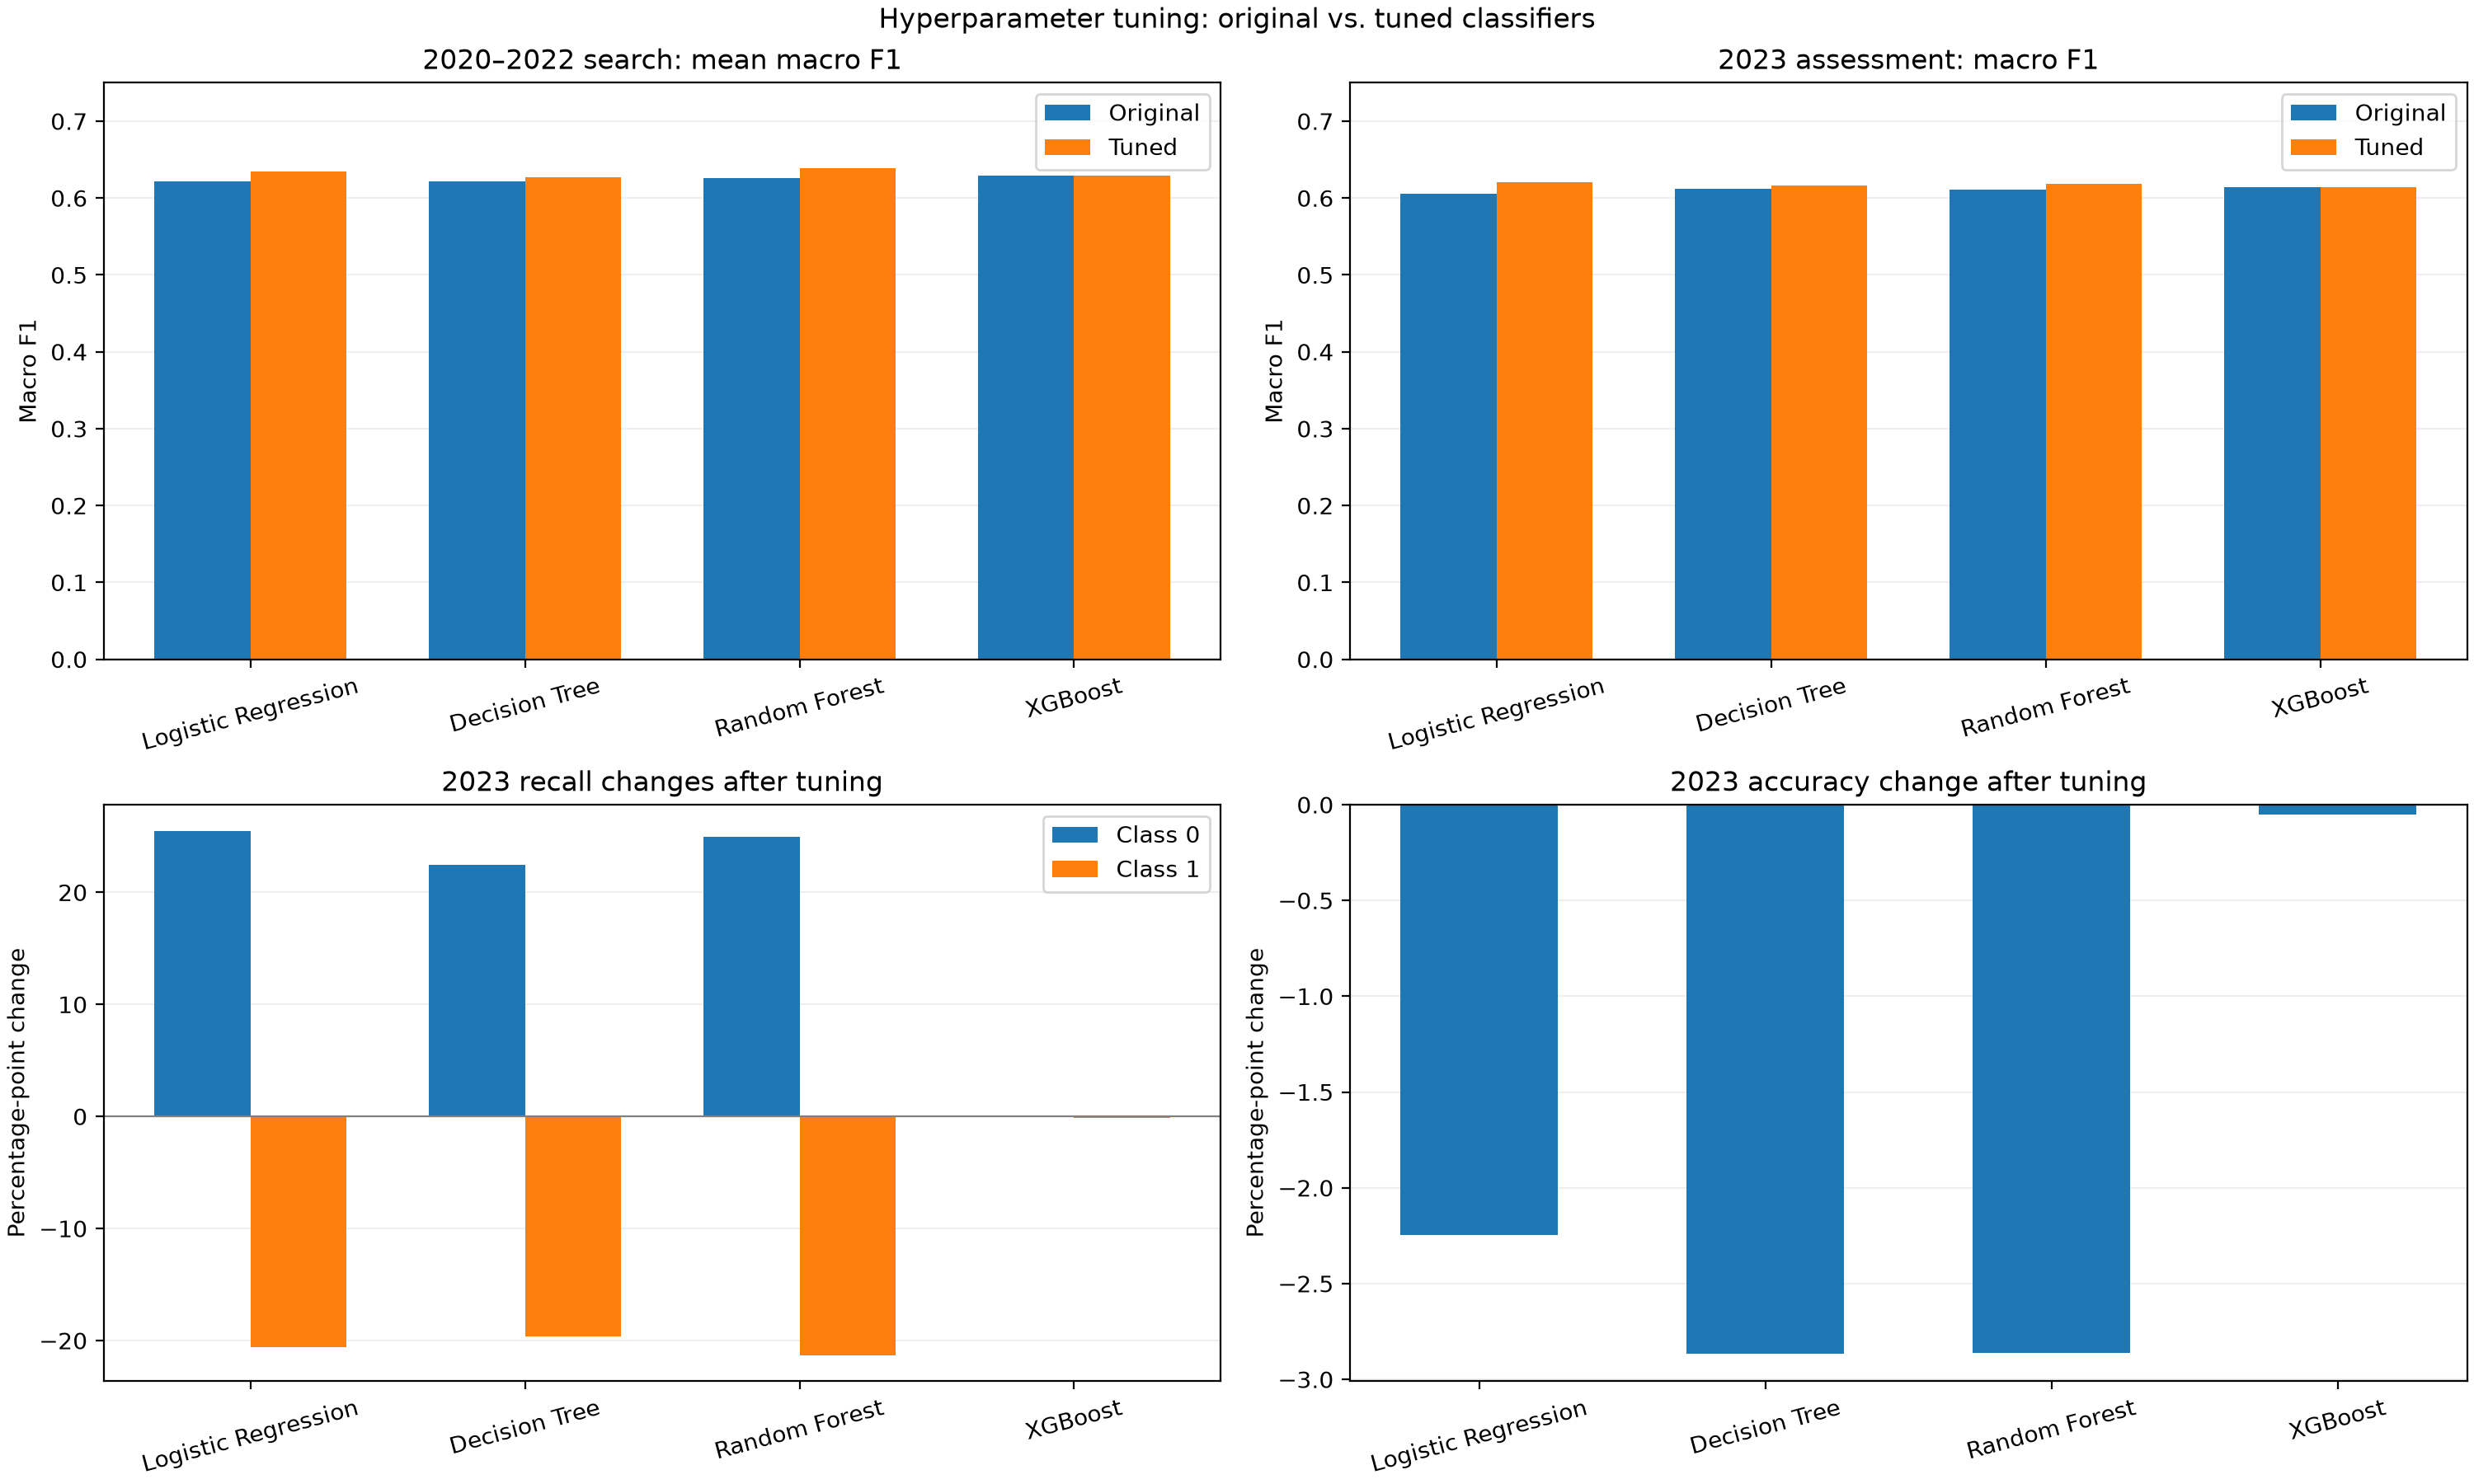

In [48]:
from IPython.display import Image

figure_path = (
    PROJECT_ROOT / "results" / "figures" / "hyperparameter_tuning_comparison.png"
)

display(Image(filename=str(figure_path)))

#### Interpretation

The figure shows that the improvements found during hyperparameter search did not always carry over to the 2023 assessment. Logistic regression showed the largest improvement in assessment macro F1 while XGBoost changed very little.

I also observed that the increases in meet-or-miss recall were accompanied by lower beat recall for logistic regression, decision tree and random forest. This helps explain why their macro F1 scores improved while overall accuracy decreased.

These results suggest that the main benefit of tuning was a different balance between the two outcome classes, rather than a substantial improvement in class discrimination.

### Conclusion

I used randomized search to tune all four classifiers and evaluated the selected configurations on the 2023 development data. Logistic regression had the largest improvement in macro F1, increasing from 0.6056 to 0.6210. Random forest and decision tree also improved while XGBoost performed slightly worse after tuning.

For the first three classifiers, tuning increased meet-or-miss recall while reducing earnings-beat recall and overall accuracy. The selected configurations included balanced class weights, which may have contributed to this shift. However, other hyperparameters also changed, so I cannot attribute the differences to class weighting alone.

ROC-AUC remained close to its original values across all four models. I found that tuning mainly affected the balance of predictions between the two classes, with limited improvement in their ability to distinguish earnings outcomes.

I will consider these tradeoffs when selecting the final model configuration for evaluation on the reserved 2024 holdout.